# Notebook 01 — Data Generation

## Purpose
Generate 50 independent synthetic emergency healthcare networks and persist them to disk for use in later notebooks.

## What this notebook does
1. Imports the graph generator from `src/`
2. Generates one example network and inspects its structure
3. Visualises the network and saves a topology figure
4. Generates all 50 trials and persists them as pickle files
5. Reloads trial 0 to verify successful persistence
6. Prints summary statistics across all 50 networks

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook is launched from project root or notebooks/
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(project_root))

import pickle
import pandas as pd
import networkx as nx

from src.config import (
    SEED, NUM_TRIALS, DATA_RAW_DIR, FIGURES_DIR, ensure_directories
)
from src.graph_generator import generate_synthetic_network, generate_trials
from src.visualize import plot_network

ensure_directories()
print(f"Project root:   {project_root}")
print(f"Data raw dir:   {DATA_RAW_DIR}")
print(f"Figures dir:    {FIGURES_DIR}")

Project root:   /Users/johen/Documents/emergency-graph-routing
Data raw dir:   /Users/johen/Documents/emergency-graph-routing/data/raw
Figures dir:    /Users/johen/Documents/emergency-graph-routing/figures


In [2]:
# Generate one example network and inspect its structure
G_example = generate_synthetic_network(seed=SEED)

degrees = [d for _, d in G_example.degree()]
print(f"Nodes:          {G_example.number_of_nodes()}")
print(f"Edges:          {G_example.number_of_edges()}")
print(f"Mean degree:    {sum(degrees) / len(degrees):.2f}")
print(f"Connected:      {nx.is_connected(G_example)}")
print(f"\nNode 0 attributes:      {G_example.nodes[0]}")
edge_01 = G_example.edges[0, 1] if G_example.has_edge(0, 1) else "no direct edge 0-1"
print(f"Edge (0,1) attributes:  {edge_01}")

Nodes:          15
Edges:          40
Mean degree:    5.33
Connected:      True

Node 0 attributes:      {'name': 'Facility_0', 'capacity': 8, 'current_load': 0, 'type': 'Hospital'}
Edge (0,1) attributes:  {'weight': 11}


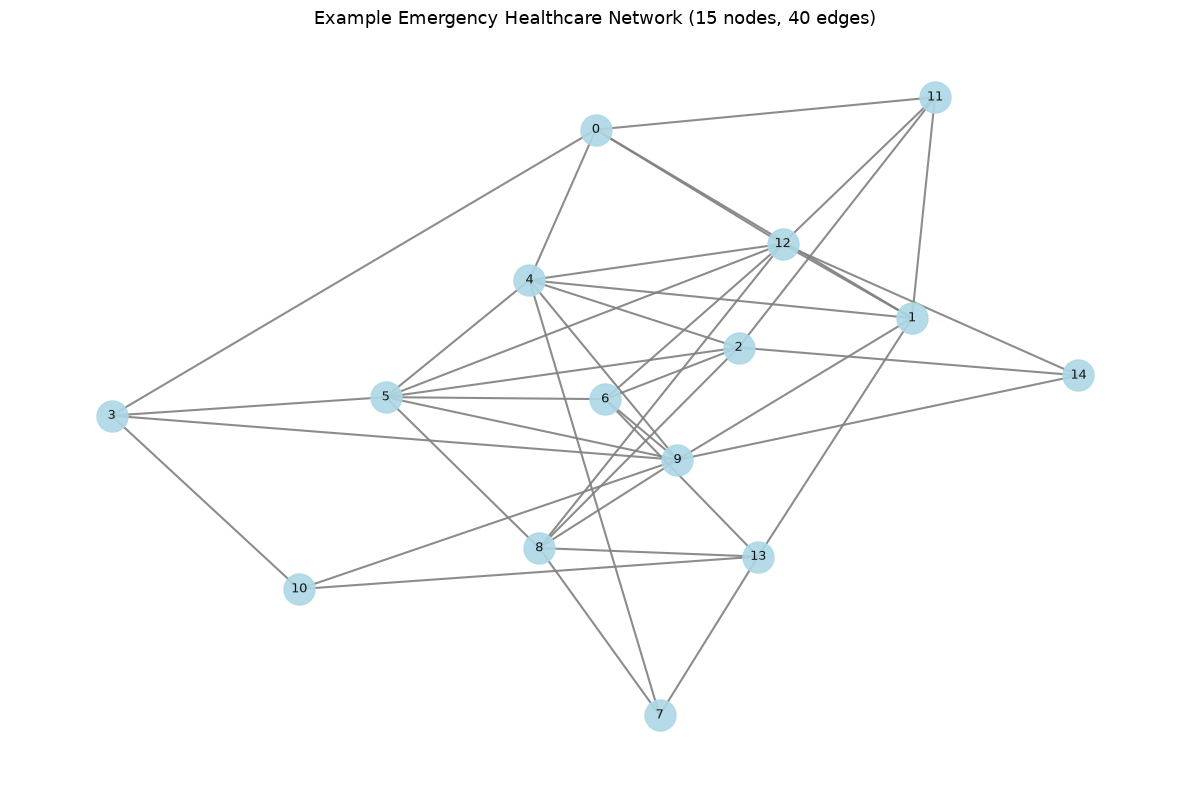

[Figure saved] /Users/johen/Documents/emergency-graph-routing/figures/01_network_topology.png
Saved: /Users/johen/Documents/emergency-graph-routing/figures/01_network_topology.png


In [3]:
# Visualise the example network and save as figure
fig_path = FIGURES_DIR / "01_network_topology.png"
plot_network(
    G_example,
    title=f"Example Emergency Healthcare Network "
          f"({G_example.number_of_nodes()} nodes, {G_example.number_of_edges()} edges)",
    filename=fig_path,
)
print(f"Saved: {fig_path}")

## Generating 50 trials

Each trial uses a different random seed (`SEED + trial_index`), so the networks are **independent** but **fully reproducible**.

Each network is pickled to disk as `data/raw/network_00.pkl`, `network_01.pkl`, ..., `network_49.pkl`.

In [4]:
# Generate all 50 networks
all_networks = generate_trials(NUM_TRIALS)
print(f"Generated {len(all_networks)} networks")

# Save each to disk
for i, G in enumerate(all_networks):
    path = DATA_RAW_DIR / f"network_{i:02d}.pkl"
    with open(path, "wb") as f:
        pickle.dump(G, f)

print(f"Saved all networks to {DATA_RAW_DIR}")

Generated 50 networks
Saved all networks to /Users/johen/Documents/emergency-graph-routing/data/raw


In [5]:
# Reload trial 0 and verify it matches the in-memory version
with open(DATA_RAW_DIR / "network_00.pkl", "rb") as f:
    G_reloaded = pickle.load(f)

assert G_reloaded.number_of_nodes() == all_networks[0].number_of_nodes()
assert G_reloaded.number_of_edges() == all_networks[0].number_of_edges()
assert G_reloaded.nodes[0] == all_networks[0].nodes[0]
print("Reload verification passed.")

Reload verification passed.


In [6]:
# Summary statistics across all 50 trials
summary_rows = []
for i, G in enumerate(all_networks):
    degrees = [d for _, d in G.degree()]
    summary_rows.append({
        "trial": i,
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "mean_degree": sum(degrees) / len(degrees),
        "connected": nx.is_connected(G),
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.describe().round(2))
print(f"\nAll connected: {summary_df['connected'].all()}")

       trial  nodes  edges  mean_degree
count  50.00   50.0  50.00        50.00
mean   24.50   15.0  41.94         5.59
std    14.58    0.0   5.53         0.74
min     0.00   15.0  28.00         3.73
25%    12.25   15.0  38.25         5.10
50%    24.50   15.0  42.50         5.67
75%    36.75   15.0  45.75         6.10
max    49.00   15.0  54.00         7.20

All connected: True


## Summary

✅ Generated 50 independent synthetic healthcare networks
✅ Saved all to `data/raw/network_XX.pkl`
✅ Verified that trial 0 reloads identically
✅ Saved topology figure: `figures/01_network_topology.png`

**Next:** Notebook 02 will compute static Dijkstra shortest paths on each of these networks.